In [2]:
from pathlib import Path
import numpy as np
import rasterio
import matplotlib.pyplot as plt

safe_dir = Path("./S2A_MSIL2A_20210625T102021_N0500_R065_T32TMR_20230319T054911.SAFE")
if not safe_dir.exists():
    raise FileNotFoundError(f"Directory {safe_dir} does not exist.")

In [3]:
b04 = next(safe_dir.glob("GRANULE/*/IMG_DATA/R10m/*B04_10m.jp2"))
b08 = next(safe_dir.glob("GRANULE/*/IMG_DATA/R10m/*B08_10m.jp2"))

with rasterio.open(b04) as src:
    red = src.read(1).astype(np.float32)
    profile = src.profile 
    red_nodata = src.nodata

with rasterio.open(b08) as src:
    nir = src.read(1).astype(np.float32)
    nir_nodata = src.nodata

print("RED shape:", red.shape, "dtype:", red.dtype, "nodata:", red_nodata, "min/max:", float(np.min(red)), float(np.max(red)))
print("NIR shape:", nir.shape, "dtype:", nir.dtype, "nodata:", nir_nodata, "min/max:", float(np.min(nir)), float(np.max(nir)))


RED shape: (10980, 10980) dtype: float32 nodata: None min/max: 0.0 17840.0
NIR shape: (10980, 10980) dtype: float32 nodata: None min/max: 0.0 16961.0


# Roi definition as the highest NDVI region

In [4]:
import numpy as np
import rasterio
from rasterio.windows import from_bounds
import matplotlib.pyplot as plt

#Defining region of interest (ROI)
roi_km = 20 #it is the size of the area we want to analyze, in kilometers, we will convert it to meters since the resolution is in meters
roi_m = roi_km * 1000 #converting km to meters
target_resolution_m = 200 #target resolution in meters (e.g., 200m) for efficient processing, we will downsample the original 10m resolution to this target resolution
real_resolution_m = 10

#Calculating the number of pixels needed to cover the ROI at the target resolution
roi_num_pixels = int(roi_m / target_resolution_m) 

with rasterio.open(b04) as src_red: 
    #original dimensions and resolution
    H, W = src_red.height, src_red.width

    #downsampled dimensions
    H_ds = int(H * real_resolution_m / target_resolution_m)
    W_ds = int(W * real_resolution_m / target_resolution_m)

    red_ds = src_red.read(1, out_shape=(H_ds, W_ds), resampling=rasterio.enums.Resampling.average).astype(np.float32)
    # trasnform is needed to georeference the pixels in the image, since we are downsampling, 
    # we need to adjust the transform to reflect the new pixel size
    transform_ds = src_red.transform * src_red.transform.scale((W / W_ds), (H / H_ds))

with rasterio.open(b08) as src_nir:
    nir_ds = src_nir.read(1, out_shape=(H_ds, W_ds), resampling=rasterio.enums.Resampling.average).astype(np.float32)
    # Here transform is no needed since we will use the same transform as the red band, 
    # but if we were to calculate it separately, it would be the same as for the red band
    # transform_ds_nir = src_nir.transform * src_nir.transform.scale((W / W_ds), (H / H_ds))

#ndvi is calculated as (NIR - RED) / (NIR + RED), we add a small value to the denominator to avoid division by zero, it is a common practice in remote sensing to avoid issues with pixels that have no data or very low values
ndvi_ds = (nir_ds - red_ds) / (nir_ds + red_ds + 1e-6) # adding a small value to avoid division by zero

# maschera semplice: escludo valori non plausibili o pixel “vuoti”
mask = np.isfinite(ndvi_ds) & (ndvi_ds > -0.2) & (ndvi_ds < 1.0) & (red_ds > 0) & (nir_ds > 0)
ndvi_ds_masked = np.where(mask, ndvi_ds, np.nan)

print("Downsampled NDVI shape:", ndvi_ds.shape, ", as 10980/20 = ", 10980/20, "\nROI window (px):", roi_num_pixels, "\nNDVI min/max (masked):", float(np.nanmin(ndvi_ds_masked)), float(np.nanmax(ndvi_ds_masked)))


Downsampled NDVI shape: (549, 549) , as 10980/20 =  549.0 
ROI window (px): 100 
NDVI min/max (masked): -0.19953051209449768 0.8134840726852417


Best window top-left corner: (160, 91), mean NDVI: 0.5774


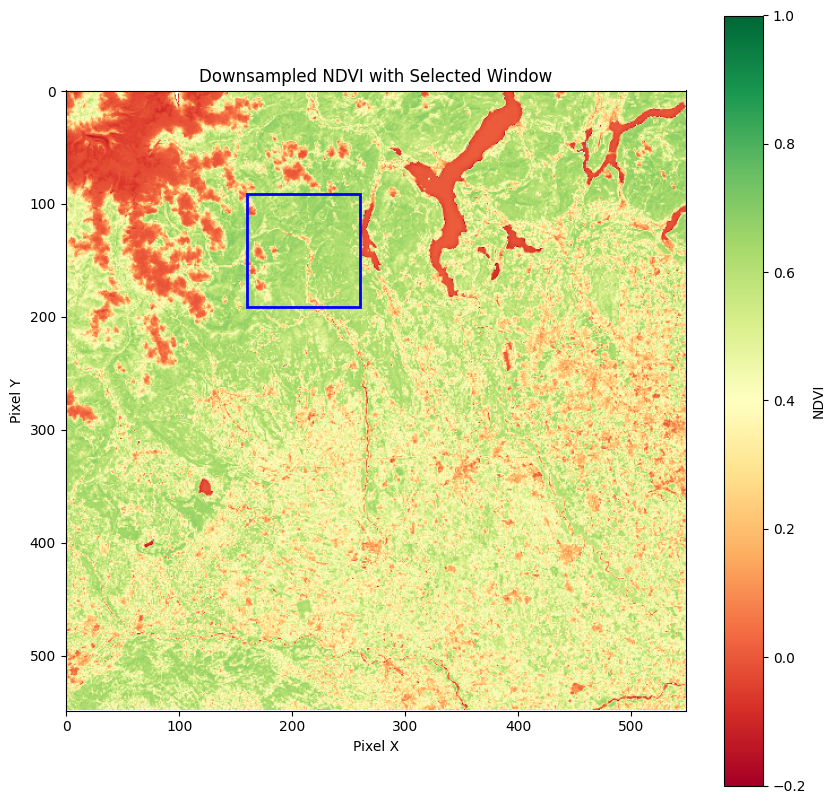

In [5]:
def window_with_highest_ndvi(ndvi_array, window_size):
    valid = np.isfinite(ndvi_array).astype(np.float32)
    a = np.nan_to_num(ndvi_array, nan=0.0).astype(np.float32)

    S = np.cumsum(np.cumsum(a, axis=0), axis=1)
    C = np.cumsum(np.cumsum(valid, axis=0), axis=1)

    def box_sum(M):
        # somma su tutte le finestre window_size×window_size
        return (M[window_size:, window_size:]
                - M[:-window_size, window_size:]
                - M[window_size:, :-window_size]
                + M[:-window_size, :-window_size])

    sum_ndvi = box_sum(S)
    count_valid = box_sum(C)

    mean_ndvi = np.where(count_valid > 0, sum_ndvi / count_valid, -np.inf)

    y, x = np.unravel_index(np.argmax(mean_ndvi), mean_ndvi.shape)
    return x, y, float(mean_ndvi[y, x])

x0_200m, y0_200m, max_ndvi_200m = window_with_highest_ndvi(ndvi_ds_masked, roi_num_pixels)
print(f"Best window top-left corner: ({x0_200m}, {y0_200m}), mean NDVI: {max_ndvi_200m:.4f}")
# here we used 200m because it is the target resolution we chose for efficient processing, 
# it allows us to analyze a larger area with less computational resources while still capturing meaningful vegetation patterns.

# Visualize the NDVI and the selected window
plt.figure(figsize=(10, 10))
plt.imshow(ndvi_ds_masked, cmap='RdYlGn', vmin=-0.2, vmax=1.0)
plt.colorbar(label='NDVI')
rect = plt.Rectangle((x0_200m, y0_200m), roi_num_pixels, roi_num_pixels, edgecolor='blue', facecolor='none', linewidth=2)
plt.gca().add_patch(rect)
plt.title('Downsampled NDVI with Selected Window')
plt.xlabel('Pixel X')
plt.ylabel('Pixel Y')
plt.show()

In [6]:
# print roi size
print(f"ROI size in pixels: {roi_num_pixels}x{roi_num_pixels}, which corresponds to {roi_km}km x {roi_km}km at {target_resolution_m}m resolution.")

ROI size in pixels: 100x100, which corresponds to 20km x 20km at 200m resolution.


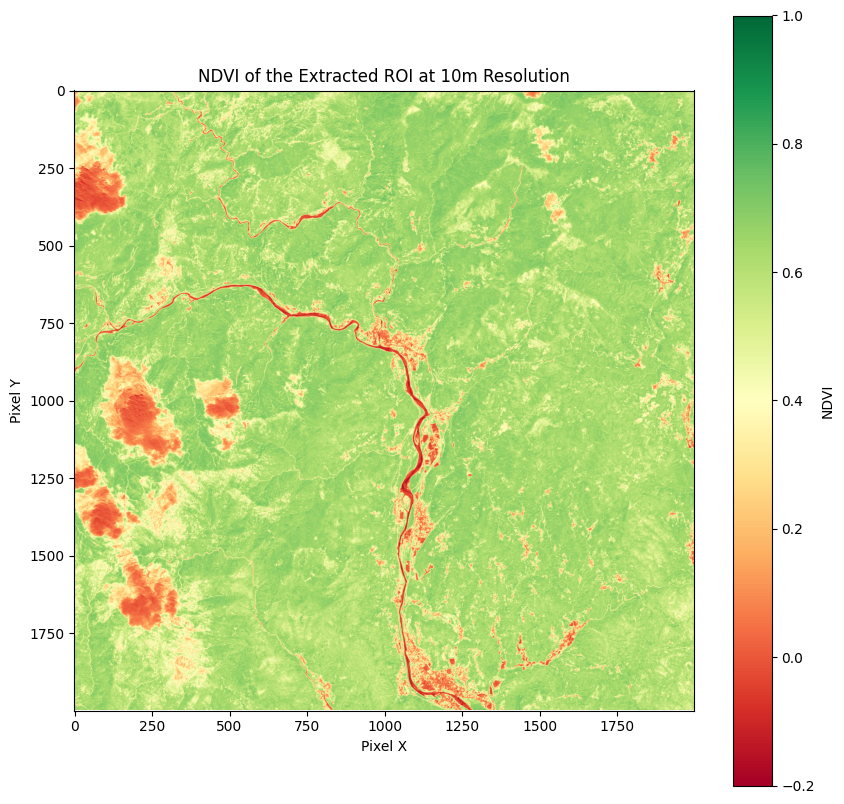

In [7]:
from rasterio.windows import Window #for extracting the roi from the original 10m resolution image

# Roi extraction
scale_factor_10m = target_resolution_m // real_resolution_m # -> 200 / 10 = 20
x0_10m = int(x0_200m * scale_factor_10m)
y0_10m = int(y0_200m * scale_factor_10m)

scale_factor_20m = target_resolution_m // 20 # -> 200 / 20 = 10
x0_20m = int(x0_200m * scale_factor_20m)
y0_20m = int(y0_200m * scale_factor_20m)

with rasterio.open(b04) as src_red: 
    # Window(col_off, row_off, width, height) 
    window_10m = Window(x0_10m, y0_10m, roi_num_pixels * scale_factor_10m, roi_num_pixels * scale_factor_10m)
    window_20m = Window(x0_20m, y0_20m, roi_num_pixels * scale_factor_20m, roi_num_pixels * scale_factor_20m)
    red_roi_10m = src_red.read(1, window=window_10m).astype(np.float32)

with rasterio.open(b08) as src_nir:
    nir_roi_10m = src_nir.read(1, window=window_10m).astype(np.float32)

ndvi_roi_10m = (nir_roi_10m - red_roi_10m) / (nir_roi_10m + red_roi_10m + 1e-6)

plt.figure(figsize=(10, 10))
plt.imshow(ndvi_roi_10m, cmap='RdYlGn', vmin=-0.2, vmax=1.0)
plt.colorbar(label='NDVI')
plt.title('NDVI of the Extracted ROI at 10m Resolution')
plt.xlabel('Pixel X')
plt.ylabel('Pixel Y')
plt.show()


Sentinel-2 MSI features 13 spectral bands with spatial resolutions of 10m, 20m, and 60m.  
The highest 10m resolution applies to visible and near-infrared (VNIR) bands (B2, B3, B4, B8),  
while red-edge/SWIR bands (B5, B6, B7, B8A, B11, B12) are 20m, and atmospheric bands (B1, B9, B10) are 60m

In [8]:
def find_10m_bands(path_to_safe):
    safe_dir = Path(path_to_safe)
    if not safe_dir.exists():
        raise FileNotFoundError(f"Directory {safe_dir} does not exist.")
    
    bands_10m = sorted(
        safe_dir.glob("GRANULE/*/IMG_DATA/R10m/*B*_10m.jp2")
    )
    return bands_10m

def find_20m_bands(path_to_safe):
    safe_dir = Path(path_to_safe)
    if not safe_dir.exists():
        raise FileNotFoundError(f"Directory {safe_dir} does not exist.")
    
    bands_20m = sorted(
        safe_dir.glob("GRANULE/*/IMG_DATA/R20m/*B*_20m.jp2")
    )

    return bands_20m

bands_10m = find_10m_bands(safe_dir)
bands_20m = find_20m_bands(safe_dir)

print("Bands at 10m resolution found:")
for band in bands_10m:
    print(band)

print("\nBands at 20m resolution found:")
for band in bands_20m:
    print(band)

Bands at 10m resolution found:
S2A_MSIL2A_20210625T102021_N0500_R065_T32TMR_20230319T054911.SAFE/GRANULE/L2A_T32TMR_A031379_20210625T102545/IMG_DATA/R10m/T32TMR_20210625T102021_B02_10m.jp2
S2A_MSIL2A_20210625T102021_N0500_R065_T32TMR_20230319T054911.SAFE/GRANULE/L2A_T32TMR_A031379_20210625T102545/IMG_DATA/R10m/T32TMR_20210625T102021_B03_10m.jp2
S2A_MSIL2A_20210625T102021_N0500_R065_T32TMR_20230319T054911.SAFE/GRANULE/L2A_T32TMR_A031379_20210625T102545/IMG_DATA/R10m/T32TMR_20210625T102021_B04_10m.jp2
S2A_MSIL2A_20210625T102021_N0500_R065_T32TMR_20230319T054911.SAFE/GRANULE/L2A_T32TMR_A031379_20210625T102545/IMG_DATA/R10m/T32TMR_20210625T102021_B08_10m.jp2

Bands at 20m resolution found:
S2A_MSIL2A_20210625T102021_N0500_R065_T32TMR_20230319T054911.SAFE/GRANULE/L2A_T32TMR_A031379_20210625T102545/IMG_DATA/R20m/T32TMR_20210625T102021_B01_20m.jp2
S2A_MSIL2A_20210625T102021_N0500_R065_T32TMR_20230319T054911.SAFE/GRANULE/L2A_T32TMR_A031379_20210625T102545/IMG_DATA/R20m/T32TMR_20210625T102021_B


Extracted bands at 20m resolution stored in dictionary with keys:
B01
B02
B03
B04
B05
B06
B07
B11
B12
B8A

Shapes of extracted 10m bands:
Band 1: (2000, 2000)
Band 2: (2000, 2000)
Band 3: (2000, 2000)
Band 4: (2000, 2000)

Shapes of extracted 20m bands:
Band 1: (1000, 1000)
Band 2: (1000, 1000)
Band 3: (1000, 1000)
Band 4: (1000, 1000)
Band 5: (1000, 1000)
Band 6: (1000, 1000)
Band 7: (1000, 1000)
Band 8: (1000, 1000)
Band 9: (1000, 1000)
Band 10: (1000, 1000)


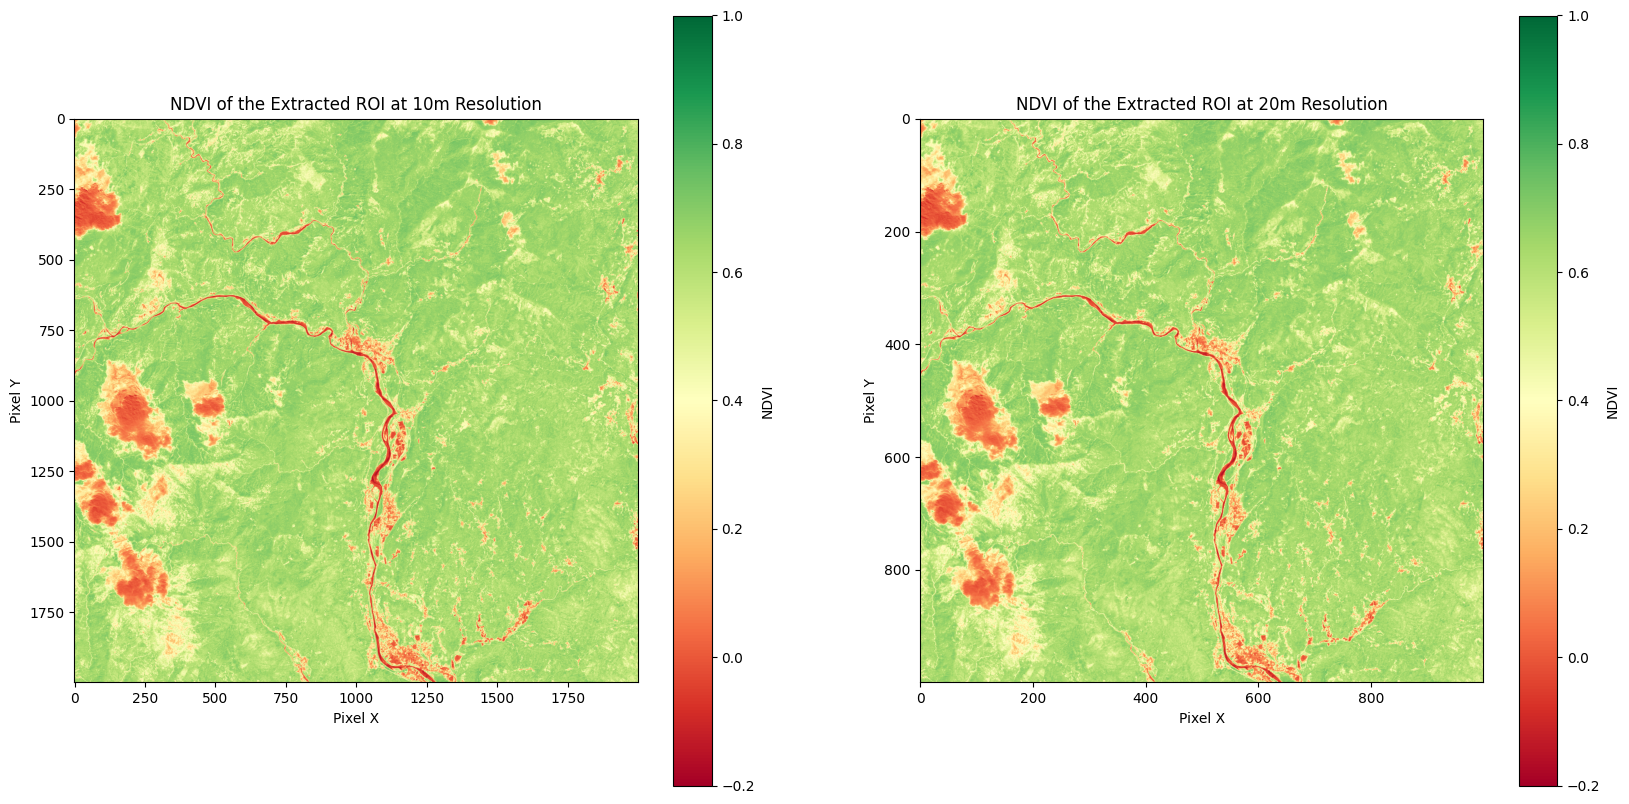

In [9]:
roi_10m_bands = []
for band_path in bands_10m:
    with rasterio.open(band_path) as src:
        band_roi = src.read(1, window=window_10m).astype(np.float32)
        roi_10m_bands.append(band_roi)

roi_20m_bands = []
for band_path in bands_20m:
    with rasterio.open(band_path) as src:
        band_roi = src.read(1, window=window_20m).astype(np.float32)
        roi_20m_bands.append(band_roi)

dict_roi20m = {}
for band_path in bands_20m:
    band_name = band_path.stem.split('_')[-2] 
    with rasterio.open(band_path) as src:
        band_roi = src.read(1, window=window_20m).astype(np.float32)
        dict_roi20m[band_name] = band_roi
print("\nExtracted bands at 20m resolution stored in dictionary with keys:")
for key in dict_roi20m.keys():
    print(key)

#useful for computing downsampled NDVI at 20m resolution by averaging the values of the 4 pixels that correspond to each pixel at 20m resolution
ndvi_roi_20m = 0.25 * (
    ndvi_roi_10m[0::2, 0::2] +
    ndvi_roi_10m[1::2, 0::2] +
    ndvi_roi_10m[0::2, 1::2] +
    ndvi_roi_10m[1::2, 1::2]
)

#sanity check on the shapes of the extracted bands
print("\nShapes of extracted 10m bands:")
for i, band in enumerate(roi_10m_bands):
    print(f"Band {i+1}: {band.shape}")
print("\nShapes of extracted 20m bands:")
for i, band in enumerate(roi_20m_bands):
    print(f"Band {i+1}: {band.shape}")

plt.subplots(1, 2, figsize=(20, 10))
plt.subplot(1, 2, 1)
plt.imshow(ndvi_roi_10m, cmap='RdYlGn', vmin=-0.2, vmax=1.0)
plt.colorbar(label='NDVI')  
plt.title('NDVI of the Extracted ROI at 10m Resolution')
plt.xlabel('Pixel X')
plt.ylabel('Pixel Y')
plt.subplot(1, 2, 2)
plt.imshow(ndvi_roi_20m, cmap='RdYlGn', vmin=-0.2, vmax=1.0)
plt.colorbar(label='NDVI')
plt.title('NDVI of the Extracted ROI at 20m Resolution')
plt.xlabel('Pixel X')
plt.ylabel('Pixel Y')
plt.show()

In [10]:
import json
from rasterio.windows import bounds as window_bounds

b05_20m = bands_20m[4] # Assuming B05 is the second band in the 20m list

with rasterio.open(b05_20m) as src20:
    roi_bounds_utm = window_bounds(window_20m, transform=src20.transform)
    roi_crs = src20.crs.to_string()
    roi_transform = src20.window_transform(window_20m)

print("CRS:", roi_crs) 
print("ROI bounds (xmin, ymin, xmax, ymax):", roi_bounds_utm)

roi_20m_data = {
    "crs": roi_crs,
    "bounds" : {
        "xmin": roi_bounds_utm[0],
        "ymin": roi_bounds_utm[1],
        "xmax": roi_bounds_utm[2],
        "ymax": roi_bounds_utm[3]
    },
    "grid20" : {
        "transform": roi_transform.to_gdal(), 
        "width": window_20m.width,
        "height": window_20m.height
    }
}

Path("roi_20m_metadata.json").write_text(json.dumps(roi_20m_data, indent=4))

CRS: EPSG:32632
ROI bounds (xmin, ymin, xmax, ymax): (431960.0, 5061800.0, 451960.0, 5081800.0)


373

# SNAP LAI

In [11]:
print(window_20m)
print("Snap coordinates for the 20m grid:")
'''
Scene start X = 1600
Scene start Y = 910
Scene end X = 2599
Scene end Y = 1909
'''

Window(col_off=1600, row_off=910, width=1000, height=1000)
Snap coordinates for the 20m grid:


'\nScene start X = 1600\nScene start Y = 910\nScene end X = 2599\nScene end Y = 1909\n'

Shape: (1000, 1000)
CRS: EPSG:32632
Transform: | 20.00, 0.00, 431960.00|
| 0.00,-20.00, 5081800.00|
| 0.00, 0.00, 1.00|
Dtype: float32
Min: -0.44200388
Max: 7.945994
Mean: 2.720043


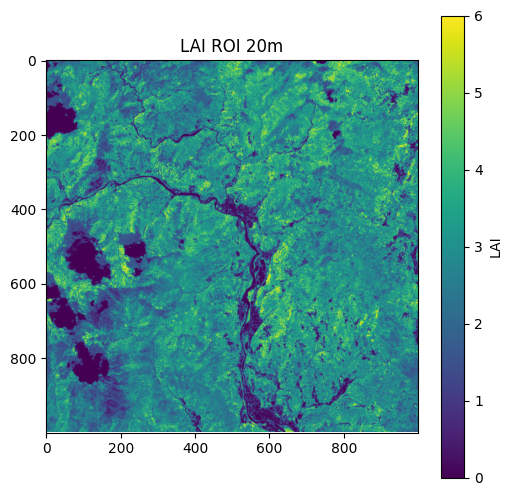

Valid pixels: 1000000
Total pixels: 1000000


In [12]:
lai_path = "LAI_ROI_20m.tif"

with rasterio.open(lai_path) as src:
    lai = src.read(1)
    print("Shape:", lai.shape)
    print("CRS:", src.crs)
    print("Transform:", src.transform)
    print("Dtype:", lai.dtype)
    print("Min:", np.nanmin(lai))
    print("Max:", np.nanmax(lai))
    print("Mean:", np.nanmean(lai))

import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.imshow(lai, cmap="viridis", vmin=0, vmax=6)
plt.colorbar(label="LAI")
plt.title("LAI ROI 20m")
plt.show()

print("Valid pixels:", np.sum(np.isfinite(lai)))
print("Total pixels:", lai.size)



Negatives: 26239  ( 2.6239 % )
P99: 4.989893  P99.9: 5.8035283
lai_clean stats:
Min: 0.0
Max: 6.0
Mean: 2.8035944


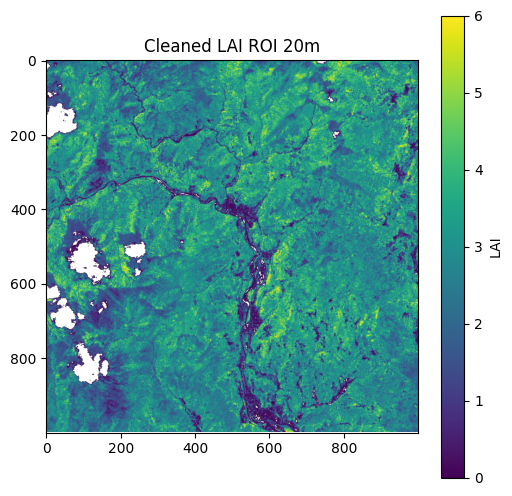

B05 min: 0.09549999982118607 max: 1.7204999923706055
B06 min: 0.0706000030040741 max: 1.6818000078201294
B07 min: 0.07329999655485153 max: 1.6663999557495117
B8A min: 0.08100000023841858 max: 1.653499960899353
B11 min: 0.11230000108480453 max: 1.5911999940872192
B12 min: 0.10660000145435333 max: 1.6131000518798828


In [13]:
import numpy as np

neg = np.sum(lai < 0)
p99 = np.nanpercentile(lai, 99)
p999 = np.nanpercentile(lai, 99.9)

print("Negatives:", neg, " (", 100*neg/lai.size, "% )")
print("P99:", p99, " P99.9:", p999)

lai_clean = lai.copy()
lai_clean[lai_clean < 0] = np.nan
lai_clean = np.clip(lai_clean, 0, 6)  # soglia conservativa

print("lai_clean stats:")
print("Min:", np.nanmin(lai_clean))
print("Max:", np.nanmax(lai_clean))
print("Mean:", np.nanmean(lai_clean))

plt.figure(figsize=(6,6))
plt.imshow(lai_clean, cmap="viridis", vmin=0, vmax=6)
plt.colorbar(label="LAI")
plt.title("Cleaned LAI ROI 20m")
plt.show()

#Scaling LAI values to be between 0 and 1 by dividing by 10,000
for k in dict_roi20m:
    dict_roi20m[k] = dict_roi20m[k] / 10000.0

# ricontrollo range
for k in ["B05","B06","B07","B8A","B11","B12"]:
    a = dict_roi20m[k]
    print(k, "min:", float(np.nanmin(a)), "max:", float(np.nanmax(a)))

# Dataset

In [14]:
feature_order = ["B05","B06","B07","B8A","B11","B12"]
X_stack = np.stack([dict_roi20m[b] for b in feature_order] + [ndvi_roi_20m], axis=-1)
#up to here, the feature array X_stack has shape (height, width, num_features) where num_features is 7 (6 bands + NDVI)

print("Stacked feature array shape:", X_stack.shape)

mask = np.isfinite(X_stack).all(axis=-1) & np.isfinite(lai_clean)

#1) apply mask to X_stack and lai_clean
X = X_stack[mask]
y = lai_clean[mask]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Valid %:", 100 * y.size / lai_clean.size)

# 2) sanity check: y range e prime righe di X
print("y min/max/mean:", float(np.min(y)), float(np.max(y)), float(np.mean(y)))
print("Any NaN in X?", np.isnan(X).any(), "Any NaN in y?", np.isnan(y).any())

Stacked feature array shape: (1000, 1000, 7)
X shape: (973761, 7)
y shape: (973761,)
Valid %: 97.3761
y min/max/mean: 0.0 6.0 2.8035943508148193
Any NaN in X? False Any NaN in y? False


In [15]:
print("Features: ", feature_order + ["NDVI"])

Features:  ['B05', 'B06', 'B07', 'B8A', 'B11', 'B12', 'NDVI']


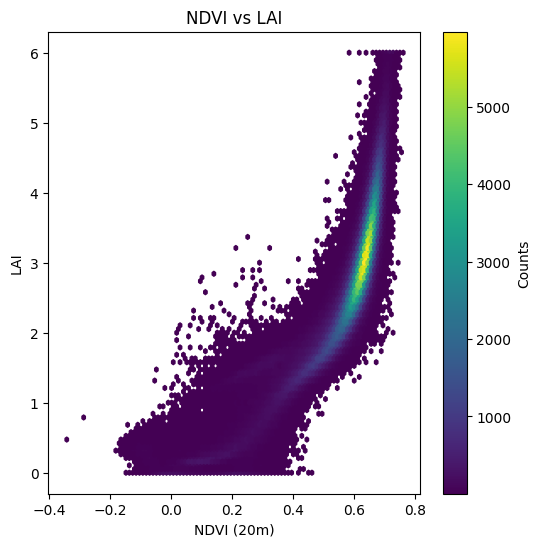

In [16]:
ndvi_flat = X[:, -1] #ndvi_20m is the last feature in X

plt.figure(figsize=(6,6))
plt.hexbin(ndvi_flat, y, gridsize=100, cmap="viridis", mincnt=1)
plt.xlabel("NDVI (20m)")
plt.ylabel("LAI")
plt.colorbar(label="Counts")
plt.title("NDVI vs LAI")
plt.show()

# Baseline Model: Polynomial Regression $LAI = f(NDVI)$

## NDVI-based LAI estimation: Polynomial Regression

The relationship between NDVI and LAI is clearly **non-linear**, as observed in the scatter plot.  
In particular, NDVI shows saturation for dense canopies (NDVI > 0.6), where large variations in LAI correspond to small changes in NDVI.

To account for this non-linearity, we adopt a **polynomial regression of degree 2**:


$LAI = \beta_0 + \beta_1 \cdot NDVI + \beta_2 \cdot NDVI^2$

This allows the model to capture curvature in the NDVI–LAI relationship.

### Why PolynomialFeatures?

The `PolynomialFeatures` transformation expands the original feature (NDVI) into:


$[1,\ NDVI,\ NDVI^2]$

The regression is still linear in the parameters (β), but non-linear in the variable NDVI.

This approach provides a fair and interpretable baseline for the NDVI-based estimation before comparing it with a multiband Machine Learning model.

### Important methodological note

The polynomial transformation is:
- **fitted only on the training set**
- **applied to the test set using the same transformation**

This avoids data leakage and ensures proper model evaluation.


Polynomial Regression (degree 2) R²: 0.8291, MSE: 0.1638


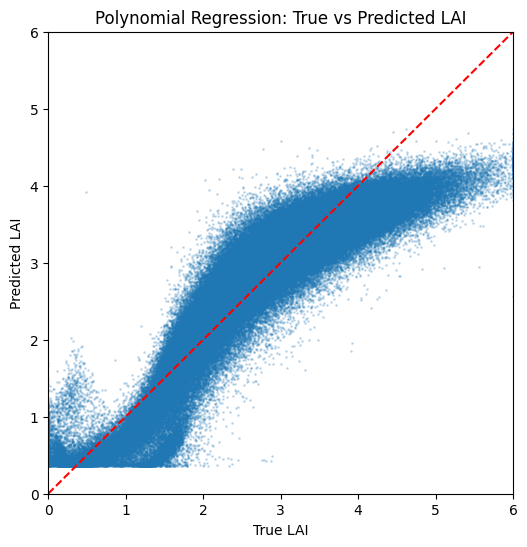

In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures

ndvi_feature = X[:, -1].reshape(-1, 1) #ndvi_20m is the last feature in X

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(ndvi_feature, y, test_size=0.3, random_state=42)

# Transforming features to include polynomial terms up to degree 2 and then fitting a linear regression model
polynomial = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = polynomial.fit_transform(X_train)
X_test_poly = polynomial.transform(X_test)

model_poly = LinearRegression()
model_poly.fit(X_train_poly, y_train)

# Final predictions and evaluation
y_pred_poly = model_poly.predict(X_test_poly)

r2_poly = r2_score(y_test, y_pred_poly)
mse_poly = mean_squared_error(y_test, y_pred_poly) 
print(f"Polynomial Regression (degree 2) R²: {r2_poly:.4f}, MSE: {mse_poly:.4f}")

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_poly, s=1, alpha=0.2) 
plt.xlabel("True LAI") 
plt.ylabel("Predicted LAI") 
plt.title("Polynomial Regression: True vs Predicted LAI") 
plt.plot([0, 6], [0, 6], 'r--') # Linea di riferimento y=x 
plt.xlim(0, 6) 
plt.ylim(0, 6) 
plt.show()

Il modello NDVI-based mostra sottostima sistematica per LAI elevati. Le predizioni tendono a comprimersi verso valori medi, evidenziando la perdita di sensibilità dell’NDVI in regime di canopy dense.  
Vuol dire che NDVI non contiene abbastanza informazione per distinguere canopy molto dense.  
Il modello può anche essere polinomiale,
ma se l’informazione in input è compressa,
l’output sarà compresso.  
Non è un limite statistico.
È un limite informativo.

# Random Forest

In [18]:
from sklearn.ensemble import RandomForestRegressor

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

rf = RandomForestRegressor(n_estimators=100, max_depth=10, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

r2_rf = r2_score(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
print(f"Random Forest R²: {r2_rf:.4f}, MSE: {mse_rf:.4f}")


Random Forest R²: 0.9717, MSE: 0.0271


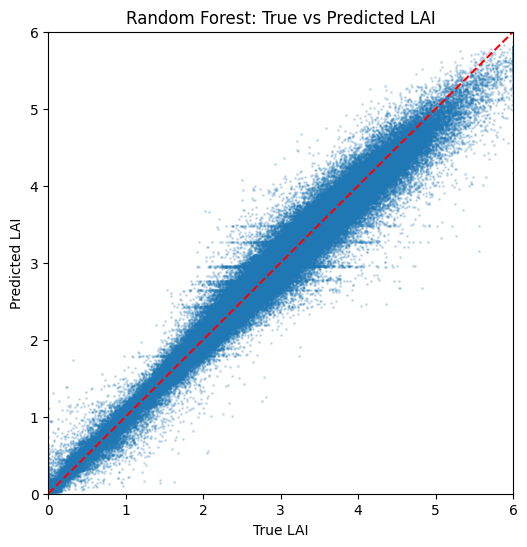

In [19]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_rf, s=1, alpha=0.2)
plt.plot([0, 6], [0, 6], 'r--')
plt.xlim(0, 6)
plt.ylim(0, 6)
plt.xlabel("True LAI")
plt.ylabel("Predicted LAI")
plt.title("Random Forest: True vs Predicted LAI")
plt.show()

In [20]:
# defining a train test and test set spatially, not randomly, to better evaluate the generalization of the model to new areas
H, W, F = X_stack.shape
trequarter_col = W * 3 // 4

train_mask = np.zeros((H, W), dtype=bool)
train_mask[:, :trequarter_col] = True  # Train on the left 75%
test_mask = ~train_mask  # Test on the right 25%

train_mask &= mask
test_mask &= mask

X_train_spatial = X_stack[train_mask]
y_train_spatial = lai_clean[train_mask]

X_test_spatial = X_stack[test_mask]
y_test_spatial = lai_clean[test_mask]

print("Spatial Train set - X shape:", X_train_spatial.shape, "y shape:", y_train_spatial.shape)
print("Spatial Test set - X shape:", X_test_spatial.shape, "y shape:", y_test_spatial.shape)

Spatial Train set - X shape: (724177, 7) y shape: (724177,)
Spatial Test set - X shape: (249584, 7) y shape: (249584,)


In [21]:
rf_spatial = RandomForestRegressor(n_estimators=100, max_depth=10, n_jobs=-1, random_state=42)
rf_spatial.fit(X_train_spatial, y_train_spatial)
y_pred_rf_spatial = rf_spatial.predict(X_test_spatial)
r2_rf_spatial = r2_score(y_test_spatial, y_pred_rf_spatial)
mse_rf_spatial = mean_squared_error(y_test_spatial, y_pred_rf_spatial)
print(f"Spatial Random Forest R²: {r2_rf_spatial:.4f}, MSE: {mse_rf_spatial:.4f}")

Spatial Random Forest R²: 0.9680, MSE: 0.0238


In [22]:
import pandas as pd

importance = rf_spatial.feature_importances_
feature_names = ["B05","B06","B07","B8A","B11","B12","NDVI"]

df_imp = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

print(df_imp)


  Feature  Importance
6    NDVI    0.904471
3     B8A    0.037704
5     B12    0.037636
1     B06    0.009841
0     B05    0.006139
4     B11    0.004108
2     B07    0.000100


L’analisi delle feature importance evidenzia che l’NDVI rappresenta la principale sorgente informativa per la stima del LAI nella ROI analizzata, mentre il contributo delle bande red-edge e SWIR risulta secondario.

## Random Forest on High LAI Analysis (LAI > 4) with spatial split

In [23]:
# ---------------------------------------------------------
# High LAI analysis (LAI > 4) with spatial split
# ---------------------------------------------------------

lai_threshold = 4.0

# Combine conditions BEFORE extracting
hl_train_mask = (lai_clean > lai_threshold) & train_mask
hl_test_mask  = (lai_clean > lai_threshold) & test_mask

# Extract spatially consistent subsets
X_train_hl = X_stack[hl_train_mask]
y_train_hl = lai_clean[hl_train_mask]

X_test_hl = X_stack[hl_test_mask]
y_test_hl = lai_clean[hl_test_mask]

print("High LAI Spatial Train set - X shape:", X_train_hl.shape, 
      "y shape:", y_train_hl.shape)
print("High LAI Spatial Test set - X shape:", X_test_hl.shape, 
      "y shape:", y_test_hl.shape)

# Train Random Forest on high LAI subset
rf_hl_spatial = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    n_jobs=-1,
    random_state=42
)

rf_hl_spatial.fit(X_train_hl, y_train_hl)

# Predictions
y_pred_hl_rf_spatial = rf_hl_spatial.predict(X_test_hl)

# Evaluation
r2_hl_rf_spatial = r2_score(y_test_hl, y_pred_hl_rf_spatial)
mse_hl_rf_spatial = mean_squared_error(y_test_hl, y_pred_hl_rf_spatial)
rmse_hl_rf_spatial = np.sqrt(mse_hl_rf_spatial)

print(f"High LAI Spatial Random Forest R²: {r2_hl_rf_spatial:.4f}")
print(f"High LAI Spatial Random Forest RMSE: {rmse_hl_rf_spatial:.4f}")

# Feature importance analysis
import pandas as pd

importances = rf_hl_spatial.feature_importances_
feature_names = ["B05","B06","B07","B8A","B11","B12","NDVI"]

df_hl_imp = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

print("\nFeature importance (High LAI subset):")
print(df_hl_imp)

print("NDVI importance in High LAI subset:", df_hl_imp[df_hl_imp["Feature"] == "NDVI"]["Importance"].values[0])
print("red-edge + SWIR bands importance in High LAI subset:", df_hl_imp[df_hl_imp["Feature"].isin(["B05","B06","B07","B8A","B11","B12"])]["Importance"].sum()) 

High LAI Spatial Train set - X shape: (68518, 7) y shape: (68518,)
High LAI Spatial Test set - X shape: (24883, 7) y shape: (24883,)
High LAI Spatial Random Forest R²: 0.8936
High LAI Spatial Random Forest RMSE: 0.1274

Feature importance (High LAI subset):
  Feature  Importance
6    NDVI    0.417731
3     B8A    0.218776
5     B12    0.162087
1     B06    0.129149
4     B11    0.046735
2     B07    0.022154
0     B05    0.003369
NDVI importance in High LAI subset: 0.41773067063845803
red-edge + SWIR bands importance in High LAI subset: 0.5822693293615421


# RF without NDVI in spatial test

In [24]:
# rimuoviamo NDVI (ultima colonna)
X_no_ndvi = X[:, :-1]

X_train, X_test, y_train, y_test = train_test_split(
    X_no_ndvi, y, test_size=0.3, random_state=42
)

rf_no_ndvi = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    n_jobs=-1,
    random_state=42
)

rf_no_ndvi.fit(X_train, y_train)

y_pred = rf_no_ndvi.predict(X_test)

print("RF without NDVI R2:", r2_score(y_test, y_pred))


RF without NDVI R2: 0.997799539416873


# Cross-Scene Validation

In [25]:
cross_path = Path("./cross-scene")
if not cross_path.exists():
    raise FileNotFoundError(f"Directory {cross_path} does not exist.")

cross_year = next(cross_path.glob("S2A_MSIL2A_20211013T101951_N0500_R065_T32TMR_20230115T052455.SAFE"))
cross_season = next(cross_path.glob("S2B_MSIL2A_20240823T101559_N0511_R065_T32TMR_20240823T145151.SAFE"))
if not cross_year.exists() or not cross_season.exists():
    raise FileNotFoundError("Required SAFE directories for cross-scene analysis not found.")


In [40]:
from pathlib import Path
import numpy as np
import rasterio
from rasterio.transform import Affine
from rasterio.warp import reproject, Resampling


def _template_from_json(grid_json: dict):
    """
    grid_json: dict come quello che hai postato (crs + grid20.transform/width/height)
    """
    crs = grid_json["crs"]
    t = grid_json["grid20"]["transform"]
    # rasterio Affine expects: (a, b, c, d, e, f) mapping to:
    # x = a*col + b*row + c
    # y = d*col + e*row + f
    # Il tuo array è [x0, px, 0, y0, 0, -px] -> Affine(px, 0, x0, 0, -px, y0)
    transform = Affine(t[1], t[2], t[0], t[4], t[5], t[3])
    width = grid_json["grid20"]["width"]
    height = grid_json["grid20"]["height"]
    return crs, transform, width, height


def _find_band_jp2_20m(safe_path: Path, band: str) -> Path:
    """
    band examples: "B05","B06","B07","B8A","B11","B12","SCL"
    Cerca in qualunque GRANULE/IMG_DATA/R20m.
    """
    band = band.upper()
    patterns = [
        f"GRANULE/*/IMG_DATA/R20m/*_{band}_20m.jp2",
        f"GRANULE/*/IMG_DATA/R20m/*{band}_20m.jp2",
    ]
    for pat in patterns:
        hits = list(safe_path.glob(pat))
        if hits:
            # se per qualche motivo ci sono più granule, prendi il primo
            return hits[0]
    raise FileNotFoundError(f"Band {band} 20m JP2 not found in SAFE: {safe_path}")

def _find_band_jp2_10m(safe_path: Path, band: str) -> Path:
    """
    band examples: "B05","B06","B07","B8A","B11","B12","SCL"
    Cerca in qualunque GRANULE/IMG_DATA/R20m.
    """
    band = band.upper()
    patterns = [
        f"GRANULE/*/IMG_DATA/R10m/*_{band}_10m.jp2",
        f"GRANULE/*/IMG_DATA/R10m/*{band}_10m.jp2",
    ]
    for pat in patterns:
        hits = list(safe_path.glob(pat))
        if hits:
            # se per qualche motivo ci sono più granule, prendi il primo
            return hits[0]
    raise FileNotFoundError(f"Band {band} 10m JP2 not found in SAFE: {safe_path}")


def extract_roi_from_safe(
    safe_path: Path,
    grid_json: dict,
    band: str,
    *,
    resampling: str = "bilinear",
    scale_reflectance: bool = True,
    dst_dtype=np.float32,
    dst_nodata=np.nan,
    spatial_resolution_m=20
):
    """
    Estrae la ROI definita dal grid_json (EPSG:32632, transform 20m, 1000x1000)
    e la ri-campiona dalla banda 20m dentro la SAFE.

    resampling: "bilinear" (consigliato per riflettanze), "nearest" (per SCL/maschere)
    scale_reflectance: True -> divide per 10000 (tipico Sentinel-2 L2A BOA)
    """
    safe_path = Path(safe_path)
    if not safe_path.exists():
        raise FileNotFoundError(safe_path)

    if spatial_resolution_m == 20:
        src_jp2 = _find_band_jp2_20m(safe_path, band)
    elif spatial_resolution_m == 10:    
        src_jp2 = _find_band_jp2_10m(safe_path, band)

    dst_crs, dst_transform, dst_width, dst_height = _template_from_json(grid_json)

    resampling_map = {
        "nearest": Resampling.nearest,
        "bilinear": Resampling.bilinear,
        "cubic": Resampling.cubic,
        "average": Resampling.average,
    }
    if resampling not in resampling_map:
        raise ValueError(f"Unsupported resampling='{resampling}'. Use one of {list(resampling_map)}.")

    dst = np.full((dst_height, dst_width), dst_nodata, dtype=dst_dtype)

    with rasterio.open(src_jp2) as src:
        src_data = src.read(1)

        # Reproject+resample direttamente sul template
        reproject(
            source=src_data,
            destination=dst,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,
            dst_transform=dst_transform,
            dst_crs=dst_crs,
            dst_nodata=dst_nodata,
            resampling=resampling_map[resampling],
        )

    # Sentinel-2 L2A BOA reflectance spesso è scalata a 0..10000
    if scale_reflectance and band != "SCL":
        # Se hai già normalizzato altrove, metti False
        dst = dst / 10000.0

    return dst


def extract_feature_stack_20m(safe_path: Path, grid_json: dict):
    """
    Estrae tutte le feature che stai usando a 20m dalla SAFE:
    B05,B06,B07,B8A,B11,B12 + SCL (utile per maschere)
    """
    bands = ["B05", "B06", "B07", "B8A", "B11", "B12"]
    X = {}
    for b in bands:
        X[b] = extract_roi_from_safe(
            safe_path, grid_json, b,
            resampling="bilinear",
            scale_reflectance=True
        )
    scl = extract_roi_from_safe(
        safe_path, grid_json, "SCL",
        resampling="nearest",
        scale_reflectance=False,
        dst_dtype=np.uint8,
        dst_nodata=255
    )
    return X, scl


In [27]:
grid_json = json.loads(Path("roi_20m_metadata.json").read_text())
X_year, scl_year = extract_feature_stack_20m(cross_year, grid_json)
X_season, scl_season = extract_feature_stack_20m(cross_season, grid_json)

print("Extracted features for cross-year and cross-season scenes.")

Extracted features for cross-year and cross-season scenes.


In [28]:
feature_order_vis = ["B05","B06","B07","B8A","B11","B12"]

X_stack_year = np.dstack([X_year[b] for b in feature_order_vis])
X_stack_season = np.dstack([X_season[b] for b in feature_order_vis])

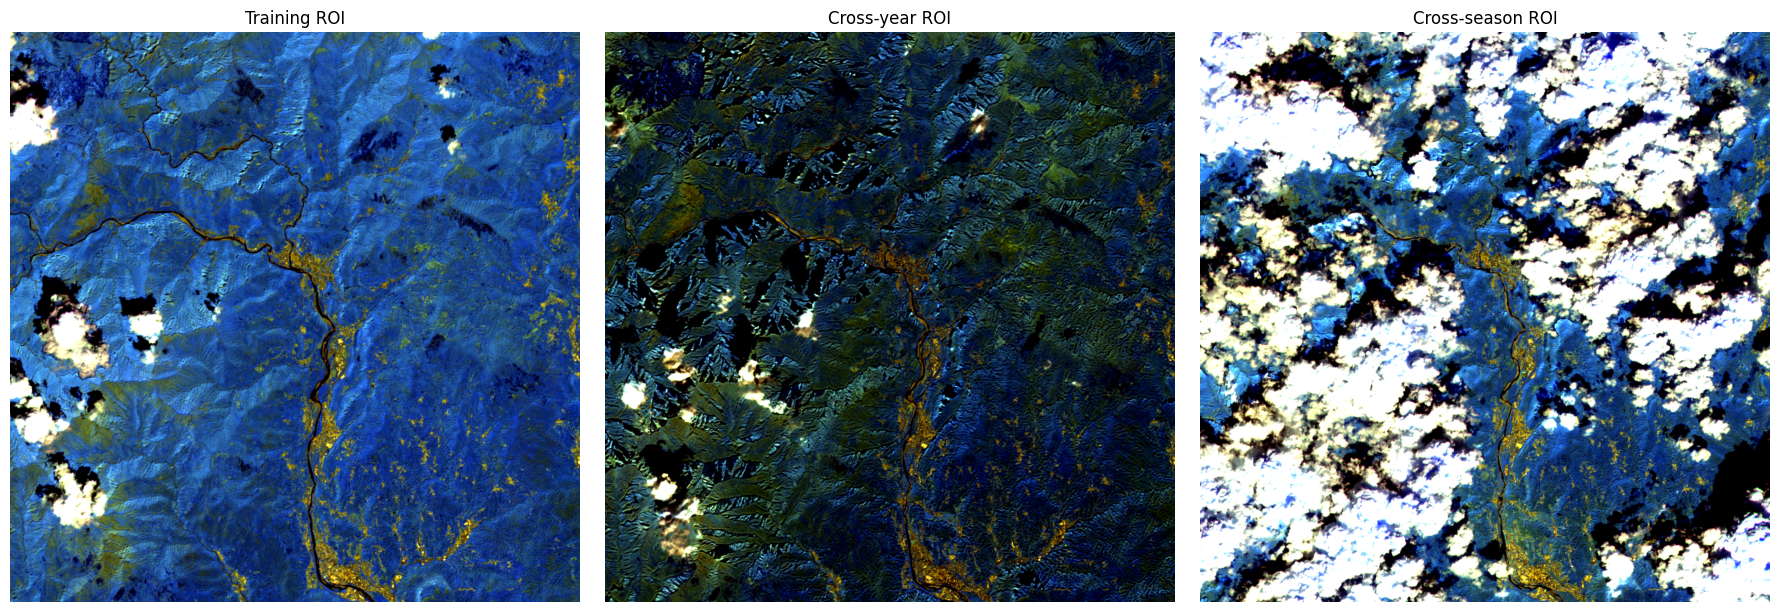

229

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def false_rgb_from_stack(stack, idx_b8a, idx_b11, idx_b12, ref_stats=None, pmin=2, pmax=98):
    B8A = stack[:, :, idx_b8a]
    B11 = stack[:, :, idx_b11]
    B12 = stack[:, :, idx_b12]

    def stretch(a, lo, hi):
        a = (a - lo) / (hi - lo + 1e-9)
        return np.clip(a, 0, 1)

    if ref_stats is None:
        ref_stats = {
            "B8A": tuple(np.nanpercentile(B8A, [pmin, pmax])),
            "B11": tuple(np.nanpercentile(B11, [pmin, pmax])),
            "B12": tuple(np.nanpercentile(B12, [pmin, pmax])),
        }

    rgb = np.dstack([
        stretch(B12, *ref_stats["B12"]),  # R
        stretch(B11, *ref_stats["B11"]),  # G
        stretch(B8A, *ref_stats["B8A"]),  # B
    ])
    return rgb, ref_stats

# Se X_stack è (1000,1000,7) e include NDVI, e tu vuoi usare le bande:
# devi sapere in che posizioni stanno B8A,B11,B12 dentro X_stack.
# Se invece usi lo stack_vis a 6 canali come sopra, gli indici sono fissi: B8A=3 B11=4 B12=5

# Per coerenza visiva, usa i 6-canali anche per training:
# (se hai già B05..B12 in X_stack, puoi creare X_stack_vis = X_stack[:, :, :6] solo se sai che i primi 6 canali sono le bande)
# oppure ricrea anche training da dict come hai fatto per year/season.

# Qui assumo che X_stack_year e X_stack_season abbiano ordine ["B05","B06","B07","B8A","B11","B12"]
idx_b8a, idx_b11, idx_b12 = 3, 4, 5

rgb_train, stats = false_rgb_from_stack(X_stack, idx_b8a, idx_b11, idx_b12)  # se X_stack ha quell'ordine nei primi 6 canali
rgb_year, _      = false_rgb_from_stack(X_stack_year, idx_b8a, idx_b11, idx_b12, ref_stats=stats)
rgb_season, _    = false_rgb_from_stack(X_stack_season, idx_b8a, idx_b11, idx_b12, ref_stats=stats)

fig, axs = plt.subplots(1, 3, figsize=(18, 6))
axs[0].imshow(rgb_train);  axs[0].set_title("Training ROI");     axs[0].axis("off")
axs[1].imshow(rgb_year);   axs[1].set_title("Cross-year ROI");   axs[1].axis("off")
axs[2].imshow(rgb_season); axs[2].set_title("Cross-season ROI"); axs[2].axis("off")
plt.tight_layout()
plt.show()

Guardando la tua terza immagine (cross-season):

-   è chiaramente molto nuvolosa, 
-   senza maschera, il modello riceve input fisicamente falsi
-   SNAP può produrre LAI anche sotto nuvole → non è fisico

Quindi il problema NON è “correzione atmosferica”.
È: evitare che pixel non validi entrino nella valutazione.

In [30]:
valid_year = np.isin(scl_year, [4, 5, 6, 7])  # vegetazione sana, guarda la tabella per i file SLC
valid_season = np.isin(scl_season, [4, 5, 6, 7])

In [ ]:
def ndvi_extraction(path_to_safe, grid_json):
    b04 = _find_band_jp2_10m(path_to_safe, "B04")
    b08 = _find_band_jp2_10m(path_to_safe, "B08")

    red = extract_roi_from_safe(
        path_to_safe, grid_json, "B04",
        resampling="bilinear",
        scale_reflectance=True, 
        spatial_resolution_m=10
    )
    nir = extract_roi_from_safe(
        path_to_safe, grid_json, "B08",
        resampling="bilinear",
        scale_reflectance=True,
        spatial_resolution_m=10
    )

    ndvi = (nir - red) / (nir + red + 1e-6)
    return ndvi

## Cross-Year Study

In [ ]:
X_year_ndvi = ndvi_extraction(cross_year, grid_json)
X_year_features = np.dstack([X_year[b] for b in feature_order_vis] + [X_year_ndvi])
X_year_valid = X_year_features[valid_year]

print("X_year shape with NDVI:", X_year_features.shape)

X_year shape with NDVI: (1000, 1000, 7)


In [45]:
print(X_year_valid.shape)

(871771, 7)
